# HypeCheck: every headline number, recomputed

This notebook recomputes HypeCheck's results from the saved per-item outputs in `research/results/`.
It needs **no Strands Decider server, no AWS account and no network** (except the optional clone
below). It costs $0 and runs in about 10 seconds.

- **The question Decider answers:** how strong is the relationship this sentence claims? The options
  are no relationship, correlational, conditional causal or direct causal. It is asked of the paper's
  conclusion and of each press-release sentence.
- **The overclaim score:** P(sentence rung > paper rung).
- **The data:** expert-labelled public data (Wright & Augenstein 2021, n = 563 test pairs), 85 real
  NIH releases, and 170 AI summaries.

[Open in Colab](https://colab.research.google.com/github/usv240/hypecheck/blob/main/notebooks/reproduce.ipynb) ·
[Repository](https://github.com/usv240/hypecheck) · [Live demo](https://d174bz5yly61n4.cloudfront.net)

In [1]:
# In Colab (or anywhere outside the repo), fetch the repository first.
import os, pathlib, subprocess, sys
if not pathlib.Path("research/reproduce.py").exists() and not pathlib.Path("../research/reproduce.py").exists():
    subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/usv240/hypecheck"], check=True)
    os.chdir("hypecheck")
if pathlib.Path("../research/reproduce.py").exists():
    os.chdir("..")
print("working in", pathlib.Path.cwd().name)

working in hypecheck


## 1. Check the files, then recompute all 22 headline numbers

`research/reproduce.py` first checks every result file against its SHA-256 in
`research/results/MANIFEST.json`. It then recomputes each number from the per-item rows, not from
saved summaries, and compares it with the value the README states.

In [2]:
out = subprocess.run([sys.executable, "research/reproduce.py"], capture_output=True, text=True)
print(out.stdout)
assert out.returncode == 0, out.stderr

manifest: all result files match
ok  Decider macro-F1 (3 labels)                             recomputed 0.4983  stated 0.498
ok  Decider AUROC, exaggerates vs not                       recomputed 0.7160  stated 0.716
ok  Decider false flags on faithful, alpha 0.10             recomputed 0.0667  stated 0.067
ok  Decider recall at alpha 0.10                            recomputed 0.3852  stated 0.385
ok  Conformal promise: false flags on 441 non-exaggerating  recomputed 0.0771  stated 0.077
ok  Claude haiku45 false flags on faithful                  recomputed 0.4493  stated 0.449
ok  Claude haiku45 macro-F1                                 recomputed 0.3578  stated 0.358
ok  Claude sonnet-4-6 false flags on faithful               recomputed 0.2957  stated 0.296
ok  Claude sonnet-4-6 macro-F1                              recomputed 0.4007  stated 0.401
ok  Claude opus-4-6 false flags on faithful                 recomputed 0.4000  stated 0.4
ok  Claude opus-4-6 macro-F1                     

## 2. False alarms on faithful press releases

Each model judges the same 345 releases that experts said are faithful to their paper. Lower is
better. A gate that cries wolf gets switched off. The Bedrock Guardrails bar uses its contextual
grounding score with the same conformal threshold fit. The keyword rule flags any sentence whose
causal verb outranks the paper's wording; it needs no model.

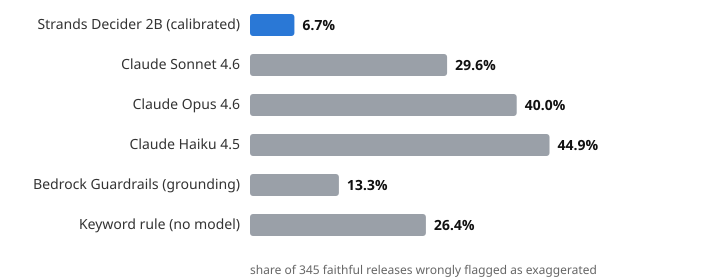

In [3]:
import csv, json
from IPython.display import SVG, display
R = pathlib.Path("research/results")
rows = lambda p: list(csv.DictReader(open(p, encoding="utf-8")))
dec = rows(R / "spike-v1/wa_items.csv")
same = [r for r in dec if r["gold"] == "same"]
BLOCK = json.load(open(R / "calibration/summary.json"))["by_alpha"]["0.1"]["threshold"]
bars = [("Strands Decider 2B (calibrated)", sum(float(r["v2_p_exag"]) > BLOCK for r in same) / len(same), True)]
for name, label in (("sonnet-4-6", "Claude Sonnet 4.6"), ("opus-4-6", "Claude Opus 4.6"), ("haiku45", "Claude Haiku 4.5")):
    llm = [r for r in rows(R / f"baseline-{name}/items.csv") if r["gold"] == "same"]
    bars.append((label, sum(r["pred"] == "exaggerates" for r in llm) / len(llm), False))
g = json.load(open(R / "guardrails/summary.json"))
bars.append(("Bedrock Guardrails (grounding)", g["guardrails"]["false_flag_same"], False))
k = json.load(open(R / "keyword-baseline/summary.json"))
bars.append(("Keyword rule (no model)", k["keyword_rule"]["false_flag_same"], False))

def bar_chart(bars, width=720, row=40, left=250, maxv=0.6):
    h = row * len(bars) + 40
    out = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{h}" font-family="sans-serif" font-size="14">']
    for i, (label, v, me) in enumerate(bars):
        y = 10 + i * row
        w = (width - left - 70) * v / maxv
        out.append(f'<text x="{left - 10}" y="{y + 19}" text-anchor="end" fill="#333">{label}</text>')
        out.append(f'<rect x="{left}" y="{y + 4}" width="{w:.1f}" height="22" rx="3" fill="{"#2a78d6" if me else "#9aa0a8"}"/>')
        out.append(f'<text x="{left + w + 8:.1f}" y="{y + 20}" font-weight="bold" fill="#111">{100 * v:.1f}%</text>')
    out.append(f'<text x="{left}" y="{h - 6}" fill="#666" font-size="12">share of 345 faithful releases wrongly flagged as exaggerated</text></svg>')
    return "".join(out)

display(SVG(bar_chart(bars)))

## 3. The promise the threshold makes, and whether it held

The block threshold is fitted by split conformal prediction on 78 training pairs that do not
exaggerate, at α = 0.10. That promises at most 10% false flags on similar text. This cell checks the
promise on the 441 unseen test pairs that do not exaggerate.

In [4]:
c = json.load(open(R / "calibration/summary.json"))["by_alpha"]
for a in ("0.05", "0.1", "0.2"):
    x = c[a]
    lo, hi = x["test_false_flag_not_overclaim_95ci"]
    print(f"alpha {a:>4}: promised <= {float(a):.0%}  measured {x['test_false_flag_not_overclaim']:.1%} "
          f"(95% CI {lo:.1%}-{hi:.1%})  recall {x['test_recall_exaggerates']:.0%}")

alpha 0.05: promised <= 5%  measured 1.6% (95% CI 0.8%-3.2%)  recall 20%
alpha  0.1: promised <= 10%  measured 7.7% (95% CI 5.6%-10.6%)  recall 39%
alpha  0.2: promised <= 20%  measured 14.3% (95% CI 11.3%-17.9%)  recall 44%


## 4. Real text nobody chose for us

- **HypeWatch:** NIH research releases checked against the papers they cite.
- **AI summaries:** Claude summaries of the same papers.

Both use the same strict public rule: a sentence must claim more than the paper's conclusion
*and* more than the strongest claim in the abstract. Neither set has human labels, so these are
Decider's flags, not ground truth.

In [5]:
hw = json.load(open("hypecheck/hypewatch.json", encoding="utf-8"))["releases"]
print(f"HypeWatch: {len(hw)} releases, {sum(len(r['sentences']) for r in hw)} sentences, "
      f"{sum(r['flagged'] > 0 for r in hw) / len(hw):.1%} with a blocked sentence")
ai = [json.loads(l) for l in open(R / "ai-summaries/items.jsonl", encoding="utf-8")]
for m in ("sonnet-4-6", "haiku-4-5"):
    flagged = [i for i in ai if any(s["zone"] == "block" for s in i["summaries"][m]["sentences"])]
    fixed = [i for i in flagged if all(s.get("rewrite_ok", True) for s in i["summaries"][m]["sentences"])]
    print(f"AI summaries, Claude {m}: {len(flagged)} of {len(ai)} had a blocked sentence; the gate fixed {len(fixed)} of {len(flagged)}")
ex = next(i for i in ai if "MOUD" in i["conclusion"])
s = next(s for s in ex["summaries"]["sonnet-4-6"]["sentences"] if s["zone"] == "block" and "save lives" in s["text"])
print("\nPaper:     ", ex["conclusion"][:160], "...")
print("Summary:   ", s["text"])
print("After gate:", s["rewrite"])

HypeWatch: 85 releases, 615 sentences, 15.3% with a blocked sentence
AI summaries, Claude sonnet-4-6: 10 of 85 had a blocked sentence; the gate fixed 9 of 10
AI summaries, Claude haiku-4-5: 9 of 85 had a blocked sentence; the gate fixed 8 of 9

Paper:      Receipt of MOUD in jail was associated with an increased likelihood of postrelease MOUD initiation and decreased risks of overdose, death from any cause, and re ...
Summary:    These findings suggest that expanding access to opioid use disorder medications in jails can save lives and reduce reincarceration, though gaps in continued treatment after release remain a challenge.
After gate: These findings suggest that expanding access to opioid use disorder medications in jails may be associated with reduced risks of overdose, death, and reincarceration, though gaps in continued treatment after release may remain a challenge.


## What this does not show

- **No press officer has used it yet.**
- **The HypeWatch and AI-summary rates have no human labels.**
- **Recall at the strict threshold is 39%,** so it is a safety net, not an editor.
- **Each experiment ran once.** The intervals are over items, not over repeated runs.

Each experiment has a pre-registration in `research/PREREGISTRATION-*.md`, written before it ran
and with its outcome appended afterwards.